# DATA 266 - Lab 2 - Part 2: Fine-tuning Stable Diffusion 1.5 with LoRA
## Notebook 1 of 3: Data preparation (task 2.1)

Part 2 has three notebooks:

1. **This notebook** - load the Pokemon captions, remove corrupted and duplicate images, split 90/10 with seed 266, resize to 512x512, describe the dataset, and write the 20 fixed prompts.
2. `p2_2_finetune.ipynb` - train two LoRA runs (rank 8 and rank 32) with the same data and the same number of steps.
3. `p2_3_generate_evaluate.ipynb` - generate images, compute the metrics, run the safety checks, and upload the results to Hugging Face.

The test images are only used for evaluation. The 20 prompts are written here, **before any training**, and committed to Git before training starts.

In [1]:
# Cell 1 - Reproducibility and environment information

import os
import sys
import random
import subprocess
from importlib.metadata import version, PackageNotFoundError

import numpy as np
import torch

SEED = 266

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


def library_version(name):
    try:
        return version(name)
    except PackageNotFoundError:
        return "not installed"


# Git commit. Git is not always on the PATH inside a notebook kernel, so a few usual places are tried
commit = ""
for git in ["git", r"C:\Program Files\Git\cmd\git.exe", os.path.expanduser(r"~\AppData\Local\Programs\Git\cmd\git.exe")]:
    try:
        result = subprocess.run([git, "rev-parse", "--short", "HEAD"], capture_output=True, text=True)
        commit = result.stdout.strip()
        break
    except FileNotFoundError:
        continue

run_info = {
    "commit": commit or "no Git repository here",
    "python": sys.version.split()[0],
    "torch": torch.__version__,
    "diffusers": library_version("diffusers"),
    "peft": library_version("peft"),
    "datasets": library_version("datasets"),
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU",
    "seed": SEED
}

print(run_info)

{'commit': '389a987', 'python': '3.11.18', 'torch': '2.14.1+cu130', 'diffusers': '0.42.1', 'peft': '0.21.2', 'datasets': '5.1.0', 'gpu': 'NVIDIA GeForce RTX 4090', 'seed': 266}


## 1. Settings and paths

In [2]:
import json
import hashlib
from pathlib import Path
from collections import Counter

import pandas as pd
import matplotlib.pyplot as plt
import imagehash
from PIL import Image
from datasets import load_dataset
from huggingface_hub import HfApi
from sklearn.model_selection import train_test_split

DATASET_NAME = "reach-vb/pokemon-blip-captions"
RESOLUTION = 512            # Stable Diffusion 1.5 works at 512x512
TEST_FRACTION = 0.10        # 90% train / 10% test

# Two images count as near-duplicates when they look the same in shape (perceptual hash)
# AND in colour (mean colour difference on a 0-255 scale). Colour is needed because the hash ignores it.
HASH_DISTANCE_LIMIT = 4     # out of 64 hash bits
COLOUR_DIFFERENCE_LIMIT = 10

DATA_DIR = Path("../data/part2")
OUT_DIR = Path("../outputs/part2")
PREP_DIR = OUT_DIR / "data_prep"
IMAGE_DIR = PREP_DIR / "images"          # processed 512x512 images (not stored in Git)
GRID_DIR = OUT_DIR / "grids"

for folder in [DATA_DIR, PREP_DIR, IMAGE_DIR / "train", IMAGE_DIR / "test", GRID_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Data folder:  ", DATA_DIR)
print("Output folder:", OUT_DIR)

C:\Users\tejas\miniconda3\envs\data266_lab2_part2\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Data folder:   ..\data\part2
Output folder: ..\outputs\part2


## 2. Load the dataset

The Pokemon BLIP captions dataset has one image and one machine-written (BLIP) caption per row. It is the dataset chosen for this lab (the alternative was the Naruto set).

In [3]:
raw = load_dataset(DATASET_NAME, split="train")

print("Rows:", len(raw))
print("Columns:", raw.column_names)
print("Example caption:", raw[0]["text"])

# The license is read from the dataset card on Hugging Face
card = HfApi().dataset_info(DATASET_NAME).card_data
print("Dataset license:", card.license)
print("Original source:", card.to_dict().get("source_datasets"))

Rows: 833
Columns: ['image', 'text']
Example caption: a drawing of a green pokemon with red eyes
Dataset license: cc-by-nc-sa-4.0
Original source: ['huggan/few-shot-pokemon']


## 3. Remove corrupted images

Every image is opened and fully decoded, and every caption is checked. Anything that fails is counted and left out. Each image is also converted to RGB (transparent parts would be put on white), cropped to a square if needed, and resized to 512x512.

In [4]:
def to_rgb_on_white(image):
    """RGB version of an image. Transparent parts are put on a white background."""
    if image.mode in ("RGBA", "LA") or (image.mode == "P" and "transparency" in image.info):
        image = image.convert("RGBA")
        background = Image.new("RGB", image.size, (255, 255, 255))
        background.paste(image, mask=image.split()[-1])
        return background
    return image.convert("RGB")


def square_resize(image, size):
    """Center-crop to a square (a no-op for square images) and resize."""
    width, height = image.size
    side = min(width, height)
    left, top = (width - side) // 2, (height - side) // 2
    return image.crop((left, top, left + side, top + side)).resize((size, size), Image.LANCZOS)


records = []        # one entry per good image
corrupted = []      # (row number, reason)
modes, original_sizes = Counter(), []

for index in range(len(raw)):
    try:
        image = raw[index]["image"]
        image.load()                                      # fully decode the file
        caption = raw[index]["text"]
        if not isinstance(caption, str) or not caption.strip():
            raise ValueError("empty caption")

        modes[image.mode] += 1
        original_sizes.append(image.size[0])
        picture = square_resize(to_rgb_on_white(image), RESOLUTION)
        records.append({
            "original_index": index,
            "caption": caption.strip(),
            "original_size": image.size[0],
            "image": picture,
            "thumb": np.asarray(picture.resize((32, 32), Image.BILINEAR), dtype=np.float32),
            "hash": np.array(imagehash.phash(picture).hash.flatten(), dtype=np.uint8),
            "md5": hashlib.md5(picture.tobytes()).hexdigest(),
        })
    except Exception as error:
        corrupted.append((index, repr(error)[:80]))

print("Images checked:        ", len(raw))
print("Corrupted / unreadable:", len(corrupted), corrupted[:3])
print("Image modes:           ", dict(modes))
print("Square images:         ", sum(1 for r in records if r["image"].size[0] == r["image"].size[1]), "of", len(records))
sizes = pd.Series(original_sizes)
print(f"Original side length: min {sizes.min()}, median {int(sizes.median())}, max {sizes.max()} pixels")
print("Smaller than 512 pixels (they are enlarged):", int((sizes < RESOLUTION).sum()))

Images checked:         833
Corrupted / unreadable: 0 []
Image modes:            {'RGB': 833}
Square images:          833 of 833
Original side length: min 272, median 1280, max 1280 pixels
Smaller than 512 pixels (they are enlarged): 279


## 4. Remove duplicate images

- **Exact duplicates:** the two 512x512 images have identical pixels.
- **Near-duplicates:** the shapes match (perceptual-hash distance at most 4 of 64 bits) **and** the colours match (mean difference below 10 out of 255). For scale, the colour difference between two unrelated images is usually above 25.

Of each group, the first image is kept.

Exact duplicates found:               0
Near-duplicate pairs found:           6
Same shape but different colour:      9 pairs (kept: different characters or colour forms)
Images removed as duplicates:         3
Images left after cleaning:           830


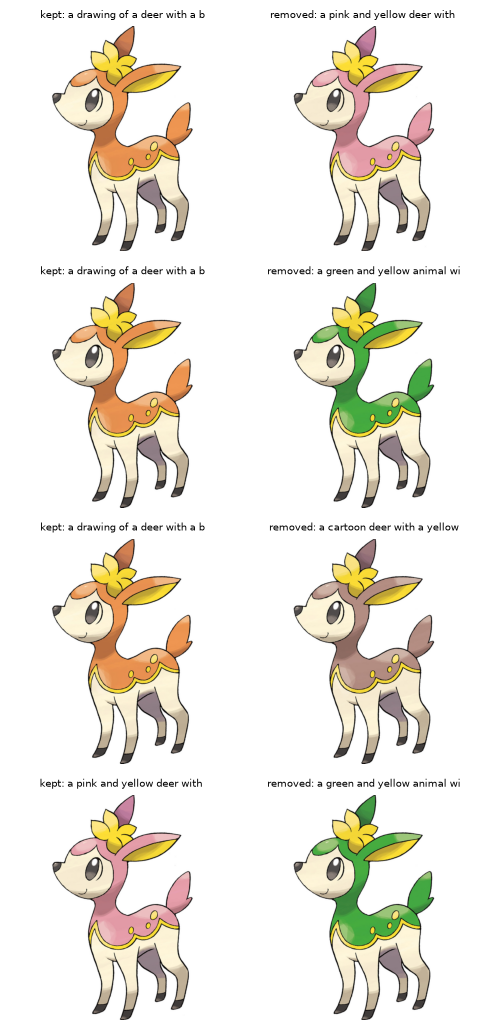

In [5]:
n = len(records)
hashes = np.stack([r["hash"] for r in records])
thumbs = np.stack([r["thumb"] for r in records])

# distance between the hashes of every pair of images
hash_distance = (hashes[:, None, :] != hashes[None, :, :]).sum(axis=-1)

# exact duplicates
first_seen, exact_pairs = {}, []
for position, record in enumerate(records):
    if record["md5"] in first_seen:
        exact_pairs.append((first_seen[record["md5"]], position))
    else:
        first_seen[record["md5"]] = position

# near-duplicates
near_pairs = []
for i in range(n):
    for j in range(i + 1, n):
        if hash_distance[i, j] <= HASH_DISTANCE_LIMIT:
            colour_difference = float(np.abs(thumbs[i] - thumbs[j]).mean())
            if colour_difference < COLOUR_DIFFERENCE_LIMIT:
                near_pairs.append((i, j, colour_difference))

# Pairs that look the same in shape but are clearly different in colour (they stay in the data)
colour_variants = sum(
    1 for i in range(n) for j in range(i + 1, n)
    if hash_distance[i, j] <= HASH_DISTANCE_LIMIT
) - len(near_pairs)

# drop the later image of every duplicate pair
drop = set()
for i, j in exact_pairs:
    drop.add(j)
for i, j, _ in near_pairs:
    if i not in drop:
        drop.add(j)

print("Exact duplicates found:              ", len(exact_pairs))
print("Near-duplicate pairs found:          ", len(near_pairs))
print("Same shape but different colour:     ", colour_variants, "pairs (kept: different characters or colour forms)")
print("Images removed as duplicates:        ", len(drop))
print("Images left after cleaning:          ", n - len(drop))

# show the images that were removed next to the one that was kept
if drop:
    shown = [(i, j) for i, j, _ in near_pairs if j in drop][:4]
    figure, axes = plt.subplots(len(shown), 2, figsize=(5, 2.6 * len(shown)))
    axes = np.atleast_2d(axes)
    for row, (kept, removed) in enumerate(shown):
        for column, (position, label) in enumerate([(kept, "kept"), (removed, "removed")]):
            axes[row, column].imshow(records[position]["image"])
            axes[row, column].set_title(f"{label}: {records[position]['caption'][:28]}", fontsize=7)
            axes[row, column].axis("off")
    plt.tight_layout()
    plt.show()

In [6]:
cleaning_summary = {
    "dataset": DATASET_NAME,
    "rows": len(raw),
    "corrupted_removed": len(corrupted),
    "exact_duplicates_removed": len(exact_pairs),
    "near_duplicates_removed": len(drop) - len(exact_pairs),
    "total_removed": len(corrupted) + len(drop),
    "images_after_cleaning": n - len(drop),
    "hash_distance_limit": HASH_DISTANCE_LIMIT,
    "colour_difference_limit": COLOUR_DIFFERENCE_LIMIT,
}
clean = [r for position, r in enumerate(records) if position not in drop]
print(json.dumps(cleaning_summary, indent=2))

{
  "dataset": "reach-vb/pokemon-blip-captions",
  "rows": 833,
  "corrupted_removed": 0,
  "exact_duplicates_removed": 0,
  "near_duplicates_removed": 3,
  "total_removed": 3,
  "images_after_cleaning": 830,
  "hash_distance_limit": 4,
  "colour_difference_limit": 10
}


## 5. Split 90% train / 10% test (seed 266)

The test images are never used for training. They are used to write the in-domain prompts and to compute KID in notebook 3.

In [7]:
train_positions, test_positions = train_test_split(
    list(range(len(clean))),
    test_size=TEST_FRACTION,
    random_state=SEED,
    shuffle=True
)
train_positions, test_positions = sorted(train_positions), sorted(test_positions)

print("Train images:", len(train_positions))
print("Test images: ", len(test_positions))
assert not set(train_positions) & set(test_positions), "train and test overlap"

Train images: 747
Test images:  83


## 6. Save the 512x512 images and the caption files

Each split gets a folder with the images and a `metadata.jsonl` file (`file_name`, `text`). The training script in notebook 2 reads the train folder directly. The images are not stored in Git (they are rebuilt by this notebook); the small csv lists are.

In [8]:
rows = {"train": [], "test": []}

for split, positions in [("train", train_positions), ("test", test_positions)]:
    metadata_lines = []
    for position in positions:
        record = clean[position]
        file_name = f"pokemon_{record['original_index']:04d}.png"
        record["image"].save(IMAGE_DIR / split / file_name)
        metadata_lines.append(json.dumps({"file_name": file_name, "text": record["caption"]}))
        rows[split].append({
            "file_name": file_name,
            "original_index": record["original_index"],
            "original_size": record["original_size"],
            "caption": record["caption"],
        })
    (IMAGE_DIR / split / "metadata.jsonl").write_text("\n".join(metadata_lines) + "\n", encoding="utf-8")
    pd.DataFrame(rows[split]).to_csv(PREP_DIR / f"split_{split}.csv", index=False)

cleaning_summary["train_images"] = len(rows["train"])
cleaning_summary["test_images"] = len(rows["test"])
(PREP_DIR / "cleaning_summary.json").write_text(json.dumps(cleaning_summary, indent=2), encoding="utf-8")

print("Saved:", IMAGE_DIR / "train", "and", IMAGE_DIR / "test")
print("Saved:", PREP_DIR / "split_train.csv", ",", PREP_DIR / "split_test.csv", ",", PREP_DIR / "cleaning_summary.json")

Saved: ..\outputs\part2\data_prep\images\train and ..\outputs\part2\data_prep\images\test
Saved: ..\outputs\part2\data_prep\split_train.csv , ..\outputs\part2\data_prep\split_test.csv , ..\outputs\part2\data_prep\cleaning_summary.json


## 7. Describe the dataset

Everything in the next two cells is computed from the cleaned data.

In [9]:
train_df, test_df = pd.DataFrame(rows["train"]), pd.DataFrame(rows["test"])
all_df = pd.concat([train_df.assign(split="train"), test_df.assign(split="test")], ignore_index=True)

words_per_caption = all_df["caption"].str.split().str.len()
stop_words = {"a", "an", "the", "of", "on", "with", "and", "is", "in", "its", "it", "to", "that", "has", "this",
              "up", "at", "for", "as", "by", "his", "her", "are", "while", "from"}
word_counts = Counter(w for c in all_df["caption"].str.lower() for w in c.split() if w not in stop_words)
colour_words = {"red", "blue", "green", "yellow", "pink", "purple", "orange", "black", "white", "brown", "gray", "grey"}
starts = all_df["caption"].str.lower()

print(f"Images: {len(all_df)} ({len(train_df)} train, {len(test_df)} test)")
print(f"Image size used for training: {RESOLUTION}x{RESOLUTION}")
print(f"Caption length: {words_per_caption.mean():.1f} words on average (min {words_per_caption.min()}, max {words_per_caption.max()})")
print(f"Different captions: {all_df['caption'].nunique()} of {len(all_df)}")
print(f"Captions starting with 'a drawing of' / 'a picture of' / 'a cartoon': "
      f"{starts.str.startswith('a drawing of').mean():.0%} / {starts.str.startswith('a picture of').mean():.0%} / {starts.str.startswith('a cartoon').mean():.0%}")
print(f"Captions that name a colour: {starts.apply(lambda c: any(w in colour_words for w in c.split())).mean():.0%}")
print(f"Captions that mention 'white background' or 'white surface': {starts.str.contains('white background|white surface').mean():.0%}")
print(f"Captions that contain the word 'pokemon': {starts.str.contains('pokemon').mean():.1%}")
print(f"Captions that name 'pikachu': {int(starts.str.contains('pikachu').sum())} (the images show many different characters)")
print("Most common words:", [w for w, _ in word_counts.most_common(15)])

# how many images have a plain white background (all four corners are almost white)
def white_corners(image):
    pixels = np.asarray(image)
    corners = [pixels[:20, :20], pixels[:20, -20:], pixels[-20:, :20], pixels[-20:, -20:]]
    return all(corner.mean() > 240 for corner in corners)

white_share = np.mean([white_corners(r["image"]) for r in clean])
low_resolution = (all_df["original_size"] < RESOLUTION).mean()
print(f"Images with a plain white background: {white_share:.0%}")
print(f"Images originally smaller than {RESOLUTION} pixels (enlarged): {low_resolution:.0%}")

Images: 830 (747 train, 83 test)
Image size used for training: 512x512
Caption length: 9.3 words on average (min 6, max 16)
Different captions: 733 of 830
Captions starting with 'a drawing of' / 'a picture of' / 'a cartoon': 38% / 3% / 23%
Captions that name a colour: 57%
Captions that mention 'white background' or 'white surface': 3%
Captions that contain the word 'pokemon': 14.0%
Captions that name 'pikachu': 15 (the images show many different characters)
Most common words: ['cartoon', 'drawing', 'character', 'blue', 'white', 'pokemon', 'eyes', 'yellow', 'green', 'big', 'bird', 'pink', 'black', 'red', 'head']
Images with a plain white background: 99%
Images originally smaller than 512 pixels (enlarged): 34%


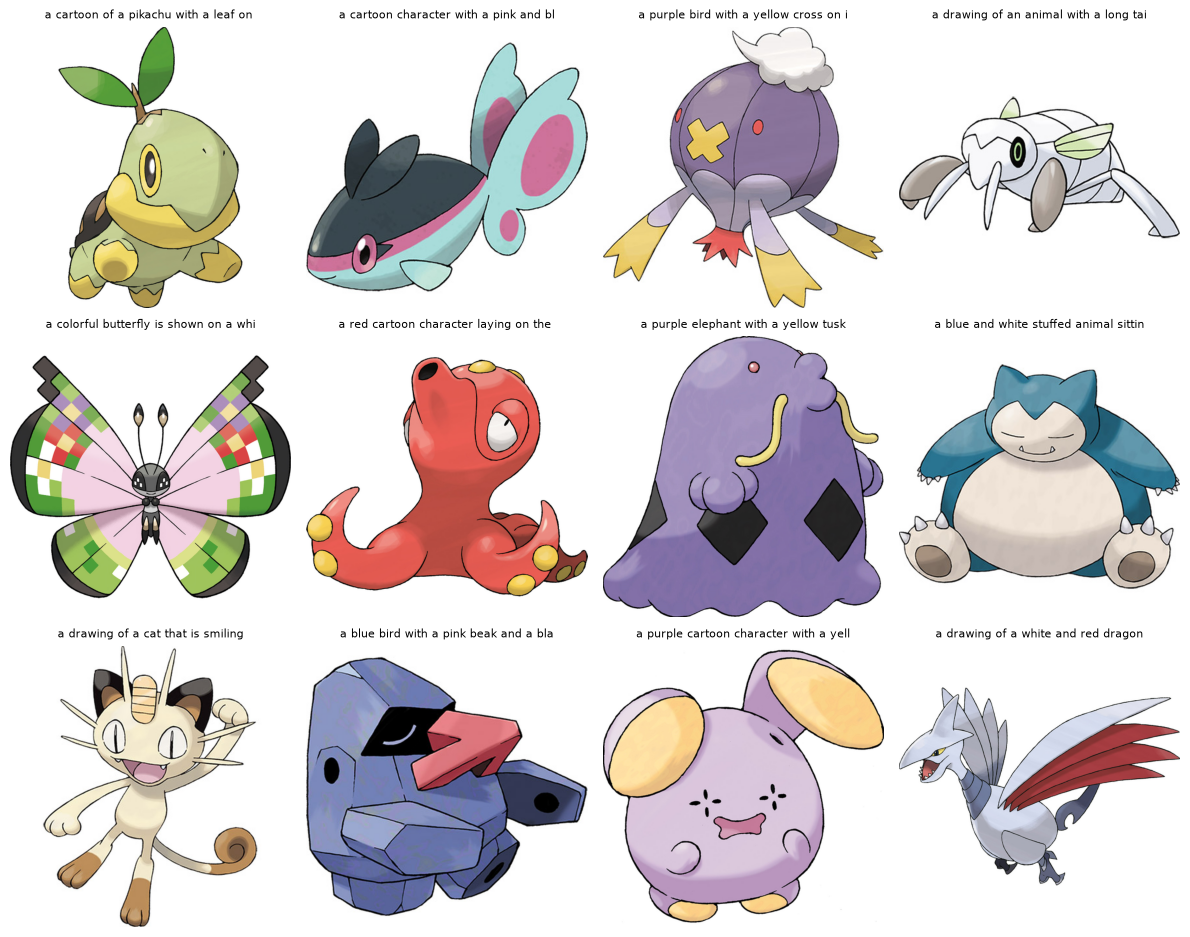

In [10]:
# A sample of training images with their captions
sample = train_df.sample(12, random_state=SEED)
figure, axes = plt.subplots(3, 4, figsize=(12, 9.5))
for axis, (_, row) in zip(axes.flat, sample.iterrows()):
    axis.imshow(Image.open(IMAGE_DIR / "train" / row["file_name"]))
    axis.set_title(row["caption"][:38], fontsize=8)
    axis.axis("off")
plt.tight_layout()
plt.savefig(GRID_DIR / "dataset_samples.png", dpi=110)
plt.show()

### Two limitations and biases of this dataset

1. **Small and very uniform.** The data is a few hundred official-style artworks of single characters on a plain white background (see the share of white backgrounds above). A model tuned on it learns a narrow look. It will probably handle prompts about scenes, backgrounds, photographs or several characters worse than the base model, and the style may leak into prompts that have nothing to do with the dataset.
2. **Weak machine-written captions and copyrighted content.** The captions come from the BLIP model, not from people. They are short and repetitive, they mostly describe colours, and many do not match the picture. In the sample above a turtle with a leaf on its head is captioned "a pikachu with a leaf" and a purple jellyfish-like character is "a purple bird". The model therefore learns a loose "colour + animal" link, and some of what it learns is wrong. All characters are copyrighted, and the dataset license (cc-by-nc-sa-4.0) allows non-commercial use only, so the models and images from this lab are for non-commercial research only.

## 8. The 20 fixed prompts (written before any training)

- **10 in-domain prompts:** taken at random (seed 266) from the **test-set captions**.
- **5 out-of-domain prompts:** nothing to do with Pokemon (photos, paintings, objects).
- **5 compositional prompts:** several objects with different colours and positions, in the style of the dataset (for example "two characters, one in red and one in blue").

They are saved to `data/part2/prompts.json` and committed to Git **before training starts**, because the Git timestamp is checked.

In [11]:
test_captions = [c for c in test_df["caption"] if len(c.split()) >= 4]
in_domain = random.Random(SEED).sample(test_captions, 10)

out_of_domain = [
    "a photograph of a snowy mountain lake at sunrise",
    "an oil painting of an old man with a white beard",
    "a red sports car parked on a city street at night",
    "a bowl of fresh fruit on a wooden table, studio photo",
    "a medieval stone castle on a green hill under a blue sky",
]

compositional = [
    "two cartoon characters, one in red and one in blue, standing side by side",
    "a small green creature sitting on top of a large yellow creature",
    "a cartoon animal holding a red balloon in one hand and a blue umbrella in the other",
    "three round creatures in a row: a pink one, a purple one and an orange one",
    "a blue dragon next to a red bird, drawn in the same style",
]

prompts = (
    [{"id": f"P{i + 1:02d}", "type": "in_domain", "prompt": p} for i, p in enumerate(in_domain)]
    + [{"id": f"P{i + 11:02d}", "type": "out_of_domain", "prompt": p} for i, p in enumerate(out_of_domain)]
    + [{"id": f"P{i + 16:02d}", "type": "compositional", "prompt": p} for i, p in enumerate(compositional)]
)

(DATA_DIR / "prompts.json").write_text(json.dumps(prompts, indent=2), encoding="utf-8")
pd.DataFrame(prompts).to_csv(DATA_DIR / "prompts.csv", index=False)

print("Saved", len(prompts), "prompts to", DATA_DIR / "prompts.json")
print(pd.DataFrame(prompts).to_string(index=False))

Saved 20 prompts to ..\data\part2\prompts.json
 id          type                                                                              prompt
P01     in_domain                                         a cartoon bird with a scarf around its neck
P02     in_domain                                   a picture of a butterfly that is orange and green
P03     in_domain                                           a pink cartoon character with a blue tail
P04     in_domain                                                a cartoon of a fire breathing dragon
P05     in_domain                                 a cartoon character sitting in the middle of a pose
P06     in_domain                                              a black and white photo of a butterfly
P07     in_domain                                       a very cute looking pokemon with a big hat on
P08     in_domain                                             a purple and black animal with big eyes
P09     in_domain                  

## 9. Summary

In [12]:
print("Rows in the dataset:           ", cleaning_summary["rows"])
print("Corrupted images removed:      ", cleaning_summary["corrupted_removed"])
print("Duplicate images removed:      ", cleaning_summary["exact_duplicates_removed"] + cleaning_summary["near_duplicates_removed"],
      f"({cleaning_summary['exact_duplicates_removed']} exact, {cleaning_summary['near_duplicates_removed']} near-duplicates)")
print("Images after cleaning:         ", cleaning_summary["images_after_cleaning"])
print("Train / test (seed 266):       ", cleaning_summary["train_images"], "/", cleaning_summary["test_images"])
print("Prompts written:               ", len(prompts), "(10 in-domain, 5 out-of-domain, 5 compositional)")
print("\nNext: commit data/part2/prompts.json and the split lists to Git, then run p2_2_finetune.ipynb.")

Rows in the dataset:            833
Corrupted images removed:       0
Duplicate images removed:       3 (0 exact, 3 near-duplicates)
Images after cleaning:          830
Train / test (seed 266):        747 / 83
Prompts written:                20 (10 in-domain, 5 out-of-domain, 5 compositional)

Next: commit data/part2/prompts.json and the split lists to Git, then run p2_2_finetune.ipynb.
